<a href="https://colab.research.google.com/github/bezawitlegesse/AWS_Ai_ml-week-03/blob/main/AWS_Ai_ml_task_week_3_spam_filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bezawitlegesse/week-3/blob/main/week-03/spam_filter.ipynb)

# Week 3 Project: Break the Spam Filter

**AI/ML AWS AASTU Cohort · Week 3 · Classical ML and Measuring Performance**

A spam filter can score very high accuracy and still be easy to fool. In this notebook I:

1. Load the **SMS Spam Collection** dataset and clean it with functions
2. Train the **10-line spam detector** (TF-IDF + Naive Bayes) and measure its accuracy
3. **Break it** with hand-written messages (spelling tricks, negation, polite business tone, and more)
4. Record what it predicted and **why it failed**
5. Bonus: try to **fix** the weaknesses and test again

Dataset: [SMS Spam Collection, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (downloaded by the code below, not stored in this repo).

## 1. Setup

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
import io
import re
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

pd.set_option("display.max_colwidth", 90)

## 2. Load the raw dataset

The code downloads the dataset from the UCI repository (the file is a zip with one tab-separated text file:
`label <tab> message`). If the first link fails it tries a backup link.

In [3]:
DATA_PAGE = "https://archive.ics.uci.edu/dataset/228/sms+spam+collection"
DATA_URLS = [
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "http://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
]


def download_bytes(url, timeout=30):
    """Download a file and return its bytes."""
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=timeout) as response:
        return response.read()


def load_raw_data(urls=DATA_URLS):
    """Download the SMS Spam Collection and return it as a raw DataFrame (label, message)."""
    last_error = None
    for url in urls:
        try:
            archive = zipfile.ZipFile(io.BytesIO(download_bytes(url)))
            text = archive.read("SMSSpamCollection").decode("utf-8", errors="replace")
            rows = [line.rstrip("\r").split("\t", 1) for line in text.split("\n") if "\t" in line]
            print("Loaded from:", url)
            return pd.DataFrame(rows, columns=["label", "message"])
        except Exception as error:
            last_error = error
            print("Could not load from", url, "->", error)
    raise RuntimeError(f"Could not download the dataset. Get it from {DATA_PAGE}") from last_error

In [4]:
raw_df = load_raw_data()
raw_df.head()

Loaded from: https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


### First look at the raw data

In [5]:
print("Shape:", raw_df.shape)
print()
raw_df.info()
print()
print("Label counts:")
print(raw_df["label"].value_counts())
print()
print("Missing values per column:")
print(raw_df.isna().sum())
print()
print("Exact duplicate messages:", raw_df.duplicated(subset="message").sum())

Shape: (5574, 2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Label counts:
label
ham     4827
spam     747
Name: count, dtype: int64

Missing values per column:
label      0
message    0
dtype: int64

Exact duplicate messages: 403


### Message length with NumPy

Do spam messages look different from normal ("ham") messages? A quick look at length, using NumPy.

 ham: mean=  71.5  median=  52.0  std=  58.3  95th percentile=   159  max=910
spam: mean= 138.7  median= 149.0  std=  28.9  95th percentile=   162  max=223


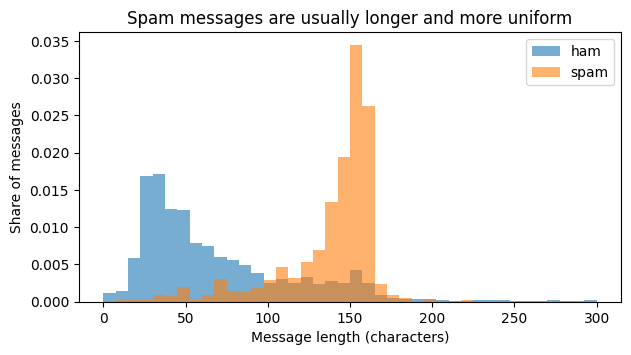

In [6]:
raw_df["length"] = raw_df["message"].str.len()

for name in ["ham", "spam"]:
    values = raw_df.loc[raw_df["label"] == name, "length"].to_numpy()
    print(f"{name:>4}: mean={np.mean(values):6.1f}  median={np.median(values):6.1f}  "
          f"std={np.std(values):6.1f}  95th percentile={np.percentile(values, 95):6.0f}  max={values.max()}")

ham_len = raw_df.loc[raw_df["label"] == "ham", "length"].to_numpy()
spam_len = raw_df.loc[raw_df["label"] == "spam", "length"].to_numpy()

plt.figure(figsize=(7, 3.5))
plt.hist(ham_len, bins=40, range=(0, 300), alpha=0.6, density=True, label="ham")
plt.hist(spam_len, bins=40, range=(0, 300), alpha=0.6, density=True, label="spam")
plt.xlabel("Message length (characters)")
plt.ylabel("Share of messages")
plt.title("Spam messages are usually longer and more uniform")
plt.legend()
plt.show()

## 3. Clean the data (with functions)

Each function fixes one problem. Together they form the pipeline `clean_sms()`:

| Function | Problem it fixes |
|---|---|
| `drop_missing` | empty or missing labels / messages |
| `normalize_text` | inconsistent case in labels, extra spaces in messages |
| `remove_duplicates` | repeated messages (they could appear in both train and test and inflate accuracy) |
| `convert_types` | text labels become a 0/1 number column, clean data types |
| `remove_length_outliers` | extremely long messages (IQR rule, computed with NumPy) |

In [7]:
def drop_missing(df):
    """Remove rows where the label or the message is missing or empty."""
    df = df.copy()
    for col in ("label", "message"):
        df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
    return df.dropna(subset=["label", "message"]).reset_index(drop=True)


def normalize_text(df):
    """Fix text and case: lower-case the label, collapse repeated spaces in the message."""
    df = df.copy()
    df["label"] = df["label"].str.lower()
    df["message"] = df["message"].str.replace(r"\s+", " ", regex=True).str.strip()
    return df


def remove_duplicates(df):
    """Remove repeated messages and keep the first one."""
    return df.drop_duplicates(subset="message", keep="first").reset_index(drop=True)


def convert_types(df):
    """Type conversion: plain text columns, a 0/1 integer target and a numeric length column."""
    df = df.copy()
    df["label"] = df["label"].astype(str)
    df["message"] = df["message"].astype(str)
    df = df[df["label"].isin(["ham", "spam"])].copy()
    df["is_spam"] = np.where(df["label"] == "spam", 1, 0).astype("int8")
    df["length"] = df["message"].str.len().astype("int32")
    return df.reset_index(drop=True)


def remove_length_outliers(df, k=3.0):
    """Outliers: drop messages that are extremely long (above Q3 + k * IQR)."""
    q1, q3 = np.percentile(df["length"], [25, 75])
    fence = q3 + k * (q3 - q1)
    too_long = df["length"] > fence
    print(f"   length fence = {fence:.0f} characters; removing {too_long.sum()} messages "
          f"({(too_long & (df['label'] == 'spam')).sum()} spam, {(too_long & (df['label'] == 'ham')).sum()} ham)")
    return df[~too_long].reset_index(drop=True)


def clean_sms(df):
    """Run the full cleaning pipeline and report how many rows each step removes."""
    steps = [
        ("drop_missing", drop_missing),
        ("normalize_text", normalize_text),
        ("remove_duplicates", remove_duplicates),
        ("convert_types", convert_types),
        ("remove_length_outliers", remove_length_outliers),
    ]
    df = df[["label", "message"]]
    print(f"start: {len(df)} rows")
    for name, step in steps:
        before = len(df)
        df = step(df)
        print(f"{name:<24} {before} -> {len(df)} rows")
    return df

In [8]:
clean_df = clean_sms(raw_df)

print()
print("Rows before cleaning:", len(raw_df))
print("Rows after cleaning: ", len(clean_df))
print()
print(clean_df["label"].value_counts())
clean_df.head()

start: 5574 rows
drop_missing             5574 -> 5574 rows
normalize_text           5574 -> 5574 rows
remove_duplicates        5574 -> 5160 rows
convert_types            5160 -> 5160 rows
   length fence = 364 characters; removing 19 messages (0 spam, 19 ham)
remove_length_outliers   5160 -> 5141 rows

Rows before cleaning: 5574
Rows after cleaning:  5141

label
ham     4499
spam     642
Name: count, dtype: int64


,label,message,is_spam,length
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",0,111
1,ham,Ok lar... Joking wif u oni...,0,29
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,1,155
3,ham,U dun say so early hor... U c already then say...,0,49
4,ham,"Nah I don't think he goes to usf, he lives around here though",0,61


## 4. Step 1: the 10-line spam detector (slide 6)

Same code as the lecture: split the data first, turn words into numbers with TF-IDF, then learn with Naive Bayes.
`emails` are the messages and `labels` are `ham` / `spam`.

In [9]:
emails = clean_df["message"]
labels = clean_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    emails, labels, test_size=0.2, random_state=42)

vec = TfidfVectorizer()                          # text -> numbers (features)
model = MultinomialNB()                          # a simple, fast classifier
model.fit(vec.fit_transform(X_train), y_train)   # learn

print("Training messages:", len(X_train))
print("Test messages:    ", len(X_test))

Training messages: 4112
Test messages:     1029


### Accuracy

In [10]:
y_pred = model.predict(vec.transform(X_test))
baseline_accuracy = accuracy_score(y_test, y_pred)
print(f"Baseline accuracy on the test set: {baseline_accuracy:.2%}")

# Is that number as impressive as it looks? Compare with a lazy filter that says "ham" every time.
always_ham = np.mean(y_test.to_numpy() == "ham")
print(f"A lazy filter that always says 'ham' would score: {always_ham:.2%}")

Baseline accuracy on the test set: 95.24%
A lazy filter that always says 'ham' would score: 87.37%


Accuracy alone can hide problems, because most messages are normal. The confusion matrix and the report below show
**what kinds of mistakes** the model makes.

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
cm_df = pd.DataFrame(cm, index=["actual ham", "actual spam"], columns=["predicted ham", "predicted spam"])
print(cm_df)
print()

tn, fp, fn, tp = cm.ravel()
print(f"Normal messages wrongly flagged as spam (false alarms): {fp}")
print(f"Spam messages that slipped through (missed spam):        {fn}")
print(f"Share of real spam that was caught (recall):             {tp / (tp + fn):.2%}")
print()
print(classification_report(y_test, y_pred, digits=3))

             predicted ham  predicted spam
actual ham             899               0
actual spam             49              81

Normal messages wrongly flagged as spam (false alarms): 0
Spam messages that slipped through (missed spam):        49
Share of real spam that was caught (recall):             62.31%

              precision    recall  f1-score   support

         ham      0.948     1.000     0.973       899
        spam      1.000     0.623     0.768       130

    accuracy                          0.952      1029
   macro avg      0.974     0.812     0.871      1029
weighted avg      0.955     0.952     0.947      1029



### What does the model look at?

Naive Bayes just counts words. Here are the words that push a message most strongly toward spam, and toward normal mail.

In [12]:
words = np.array(vec.get_feature_names_out())
spam_i = list(model.classes_).index("spam")
ham_i = list(model.classes_).index("ham")
log_ratio = model.feature_log_prob_[spam_i] - model.feature_log_prob_[ham_i]

order = np.argsort(log_ratio)
print("Strongest SPAM words:", ", ".join(words[order[::-1][:15]]))
print("Strongest HAM words: ", ", ".join(words[order[:15]]))

Strongest SPAM words: claim, prize, www, uk, 150p, 18, tone, guaranteed, cs, txt, 1000, co, 500, awarded, service
Strongest HAM words:  gt, lt, my, da, come, he, ok, lor, but, me, oh, ll, home, how, so


## 5. Your task: break the spam filter

First, the two examples from the slide:

In [13]:
tests = [
    "Cl@im your fr33 g1ft card now",
    "Not free, just confirming lunch at 1pm",
]
print(model.predict(vec.transform(tests)))

['ham' 'ham']


Now a bigger set of attacks. Each message has the label it **should** get (`expected`) and my idea of why it might fool
a model that only counts words. These reasons are hypotheses, so I check them against what the model actually does.

In [14]:
ATTACKS = [
    # ---- spam that may slip through
    {"category": "Spelling trick", "expected": "spam",
     "message": "Cl@im your fr33 g1ft card now",
     "why": "Spelling trick: 'Cl@im', 'fr33' and 'g1ft' never appeared in the training data, so the model cannot link them to claim, free and gift."},
    {"category": "Heavy spelling trick", "expected": "spam",
     "message": "Y0u h4ve w0n 5000 b1rr! C@ll n0w to cl@im y0ur pr1ze",
     "why": "Almost every spam word is disguised, so very few known spam words are left for the model to count."},
    {"category": "Spaced-out letters", "expected": "spam",
     "message": "F R E E entry in our weekly draw. R E P L Y now to join",
     "why": "The vectorizer sees single letters instead of the words FREE and REPLY, so the spam signal disappears."},
    {"category": "Polite business tone", "expected": "spam",
     "message": "Dear customer, we are pleased to inform you that your account has been selected for a reward. Kindly confirm your details at your earliest convenience.",
     "why": "The spam in the training data is loud (FREE, WIN, URGENT). Calm, formal wording looks like normal mail."},
    {"category": "Modern phishing", "expected": "spam",
     "message": "We noticed unusual activity on your bank account. Please verify your identity using the secure link below to avoid suspension.",
     "why": "The dataset has older UK text messages, so modern phishing wording is mostly unseen."},
    {"category": "Local context", "expected": "spam",
     "message": "Dear customer, you have won 5000 birr in our mobile promotion. Visit the nearest shop with your ID to receive your prize.",
     "why": "Prize and currency wording (birr, shop, ID) is different from the UK-style spam the model learned from."},
    {"category": "Friendly tone", "expected": "spam",
     "message": "Hey, it's Sarah from the gym! Your trial is ready, just reply YES and we will add 50 credit to your account.",
     "why": "It starts like a personal text, and a few spam words cannot outweigh the many normal words."},
    # ---- normal mail that may get flagged
    {"category": "Negation", "expected": "ham",
     "message": "Not free, just confirming lunch at 1pm",
     "why": "The model counts words and ignores order, so it sees 'free' and misses the 'not'."},
    {"category": "Spam words, normal meaning", "expected": "ham",
     "message": "Congratulations! I won the quiz at school. Call me now, I will claim my certificate tomorrow.",
     "why": "'Congratulations', 'won', 'call', 'now' and 'claim' are strong spam words, and the model cannot see that the context is friendly."},
    {"category": "Ambiguous word 'free'", "expected": "ham",
     "message": "I am free tomorrow, call me and we can pick up the free tickets from the office.",
     "why": "'free' and 'call' are strong spam signals, and the model cannot tell that 'free tomorrow' just means available."},
    {"category": "Formal normal mail", "expected": "ham",
     "message": "Dear student, your exam timetable has been posted. Please reply to confirm that you received this message.",
     "why": "'reply' and 'confirm' are common in spam, and the model has seen few formal normal messages."},
    {"category": "Delivery message", "expected": "ham",
     "message": "Your parcel is waiting at the front desk. Please text me to confirm what time you will collect it.",
     "why": "'parcel', 'text' and 'confirm' appear often in delivery spam, so a real delivery message looks suspicious."},
    {"category": "Money talk", "expected": "ham",
     "message": "Please send 500 birr for the book today, I will pay you back when I get my allowance.",
     "why": "Money and payment words look like spam to a model that only counts words."},
]

attack_df = pd.DataFrame(ATTACKS)
spam_col = list(model.classes_).index("spam")
attack_df["model_said"] = model.predict(vec.transform(attack_df["message"]))
attack_df["spam_probability"] = model.predict_proba(vec.transform(attack_df["message"]))[:, spam_col].round(3)
attack_df["fooled"] = attack_df["model_said"] != attack_df["expected"]

print(f"Messages that fooled the model: {attack_df['fooled'].sum()} of {len(attack_df)}")
attack_df[["category", "message", "expected", "model_said", "spam_probability", "fooled"]]

Messages that fooled the model: 6 of 13


,category,message,expected,model_said,spam_probability,fooled
0,Spelling trick,Cl@im your fr33 g1ft card now,spam,ham,0.064,True
1,Heavy spelling trick,Y0u h4ve w0n 5000 b1rr! C@ll n0w to cl@im y0ur pr1ze,spam,ham,0.094,True
2,Spaced-out letters,F R E E entry in our weekly draw. R E P L Y now to join,spam,spam,0.689,False
3,Polite business tone,"Dear customer, we are pleased to inform you that your account has been selected for a ...",spam,ham,0.079,True
4,Modern phishing,We noticed unusual activity on your bank account. Please verify your identity using th...,spam,ham,0.156,True
5,Local context,"Dear customer, you have won 5000 birr in our mobile promotion. Visit the nearest shop ...",spam,ham,0.490,True
6,Friendly tone,"Hey, it's Sarah from the gym! Your trial is ready, just reply YES and we will add 50 c...",spam,ham,0.030,True
7,Negation,"Not free, just confirming lunch at 1pm",ham,ham,0.012,False
8,"Spam words, normal meaning","Congratulations! I won the quiz at school. Call me now, I will claim my certificate to...",ham,ham,0.140,False
9,Ambiguous word 'free',"I am free tomorrow, call me and we can pick up the free tickets from the office.",ham,ham,0.006,False


### Why did it fail?

In [15]:
for _, row in attack_df[attack_df["fooled"]].iterrows():
    print(f'[{row["category"]}] "{row["message"]}"')
    print(f'   model said: {row["model_said"]} (spam probability {row["spam_probability"]}), should be: {row["expected"]}')
    print(f'   likely reason: {row["why"]}')
    print()

survived = attack_df[~attack_df["fooled"]]
if len(survived):
    print("The model handled these correctly (it was NOT fooled):")
    for _, row in survived.iterrows():
        print(f'   [{row["category"]}] {row["message"][:70]}')

if attack_df["fooled"].sum() < 3:
    print()
    print("The deliverable needs 3 or more tricks that work. Add more messages to ATTACKS and run the cells again.")

[Spelling trick] "Cl@im your fr33 g1ft card now"
   model said: ham (spam probability 0.064), should be: spam
   likely reason: Spelling trick: 'Cl@im', 'fr33' and 'g1ft' never appeared in the training data, so the model cannot link them to claim, free and gift.

[Heavy spelling trick] "Y0u h4ve w0n 5000 b1rr! C@ll n0w to cl@im y0ur pr1ze"
   model said: ham (spam probability 0.094), should be: spam
   likely reason: Almost every spam word is disguised, so very few known spam words are left for the model to count.

[Polite business tone] "Dear customer, we are pleased to inform you that your account has been selected for a reward. Kindly confirm your details at your earliest convenience."
   model said: ham (spam probability 0.079), should be: spam
   likely reason: The spam in the training data is loud (FREE, WIN, URGENT). Calm, formal wording looks like normal mail.

[Modern phishing] "We noticed unusual activity on your bank account. Please verify your identity using the secure link

### Results table for the README

The cell below prints the table in the format the deliverable asks for. Copy it into `README.md`.

In [16]:
NAME = {"ham": "not spam", "spam": "spam"}


def to_markdown_table(rows):
    """Build the 'My message / Model said / Should be / Why it failed' table."""
    lines = ["| My message | Model said | Should be | Why it failed |", "|---|---|---|---|"]
    for _, row in rows.iterrows():
        message = row["message"].replace("|", "\\|")
        lines.append(f'| "{message}" | {NAME[row["model_said"]]} | {NAME[row["expected"]]} | {row["why"]} |')
    return "\n".join(lines)


print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print()
print(to_markdown_table(attack_df[attack_df["fooled"]]))

Baseline accuracy: 95.24%

| My message | Model said | Should be | Why it failed |
|---|---|---|---|
| "Cl@im your fr33 g1ft card now" | not spam | spam | Spelling trick: 'Cl@im', 'fr33' and 'g1ft' never appeared in the training data, so the model cannot link them to claim, free and gift. |
| "Y0u h4ve w0n 5000 b1rr! C@ll n0w to cl@im y0ur pr1ze" | not spam | spam | Almost every spam word is disguised, so very few known spam words are left for the model to count. |
| "Dear customer, we are pleased to inform you that your account has been selected for a reward. Kindly confirm your details at your earliest convenience." | not spam | spam | The spam in the training data is loud (FREE, WIN, URGENT). Calm, formal wording looks like normal mail. |
| "We noticed unusual activity on your bank account. Please verify your identity using the secure link below to avoid suspension." | not spam | spam | The dataset has older UK text messages, so modern phishing wording is mostly unseen. |
| "Dear cu

## 6. Bonus: can we fix it?

Each trick suggests a fix:

| Weakness | Fix |
|---|---|
| Spelling tricks (`fr33`, `g1ft`) | `deleet_text()` turns digits and symbols inside words back into letters (`fr33` becomes `free`) |
| Negation and phrases (`not free`) | use **word pairs** (bigrams), so "not free" is one feature |
| Disguised or spaced words | add **character n-grams**, which look at pieces of words |
| Only counting words | use Logistic Regression, which weighs all features together |

I train the improved model on the **same training split** and test it on the same test set and the same attack messages.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support
from sklearn.pipeline import FeatureUnion, Pipeline

LEET_MAP = str.maketrans({"0": "o", "1": "i", "3": "e", "4": "a", "5": "s", "@": "a", "$": "s"})


def deleet_text(text):
    """Undo common spelling tricks inside words: Cl@im -> Claim, fr33 -> free, g1ft -> gift."""
    def fix(match):
        token = match.group(0)
        letters = sum(ch.isalpha() for ch in token)
        looks_like_time = re.fullmatch(r"\d+[a-zA-Z]{1,3}", token)      # 1pm, 5pm, 2nd, 10km
        if letters >= 2 and not looks_like_time and any(ch in "01345@$" for ch in token):
            return token.translate(LEET_MAP)
        return token
    return re.sub(r"\S+", fix, text)


print(deleet_text("Cl@im your fr33 g1ft card now"))
print(deleet_text("Not free, just confirming lunch at 1pm"))

Claim your free gift card now
Not free, just confirming lunch at 1pm


In [18]:
improved = Pipeline([
    ("features", FeatureUnion([
        ("words", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
    ])),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
improved.fit(X_train.map(deleet_text), y_train)
improved_pred = improved.predict(X_test.map(deleet_text))


def scores(name, y_true, y_hat):
    """Collect the numbers we want to compare."""
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_hat, pos_label="spam", average="binary")
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=["ham", "spam"]).ravel()
    return {"model": name, "accuracy": round(accuracy_score(y_true, y_hat), 4),
            "spam precision": round(precision, 3), "spam recall": round(recall, 3),
            "false alarms": int(fp), "missed spam": int(fn)}


comparison = pd.DataFrame([
    scores("baseline (TF-IDF + Naive Bayes)", y_test, y_pred),
    scores("improved (words + chars + Logistic Regression)", y_test, improved_pred),
])
comparison

,model,accuracy,spam precision,spam recall,false alarms,missed spam
0,baseline (TF-IDF + Naive Bayes),0.9524,1.000,0.623,0,49
1,improved (words + chars + Logistic Regression),0.9903,0.976,0.946,3,7


In [19]:
attack_df["improved_said"] = improved.predict(attack_df["message"].map(deleet_text))
attack_df["improved_fooled"] = attack_df["improved_said"] != attack_df["expected"]

print(f"Baseline fooled on {attack_df['fooled'].sum()} of {len(attack_df)} attack messages")
print(f"Improved fooled on {attack_df['improved_fooled'].sum()} of {len(attack_df)} attack messages")
print()
attack_df[["category", "message", "expected", "model_said", "improved_said"]]

Baseline fooled on 6 of 13 attack messages
Improved fooled on 3 of 13 attack messages



,category,message,expected,model_said,improved_said
0,Spelling trick,Cl@im your fr33 g1ft card now,spam,ham,spam
1,Heavy spelling trick,Y0u h4ve w0n 5000 b1rr! C@ll n0w to cl@im y0ur pr1ze,spam,ham,spam
2,Spaced-out letters,F R E E entry in our weekly draw. R E P L Y now to join,spam,spam,spam
3,Polite business tone,"Dear customer, we are pleased to inform you that your account has been selected for a ...",spam,ham,ham
4,Modern phishing,We noticed unusual activity on your bank account. Please verify your identity using th...,spam,ham,ham
5,Local context,"Dear customer, you have won 5000 birr in our mobile promotion. Visit the nearest shop ...",spam,ham,spam
6,Friendly tone,"Hey, it's Sarah from the gym! Your trial is ready, just reply YES and we will add 50 c...",spam,ham,spam
7,Negation,"Not free, just confirming lunch at 1pm",ham,ham,ham
8,"Spam words, normal meaning","Congratulations! I won the quiz at school. Call me now, I will claim my certificate to...",ham,ham,ham
9,Ambiguous word 'free',"I am free tomorrow, call me and we can pick up the free tickets from the office.",ham,ham,ham


**Be careful with these numbers.** The attack messages are a tiny hand-made sample, not a proper benchmark, and I chose them because I know how
word-counting models behave. A better test would use many more messages from real senders.

## 7. Try your own messages

Type any message and see what both models say.

In [20]:
def check(message):
    """Show the verdict of the baseline and the improved model for one message."""
    base_label = model.predict(vec.transform([message]))[0]
    base_prob = model.predict_proba(vec.transform([message]))[0][spam_col]
    better_label = improved.predict([deleet_text(message)])[0]
    better_prob = improved.predict_proba([deleet_text(message)])[0][list(improved.classes_).index("spam")]
    print(f'"{message}"')
    print(f"   baseline: {base_label:<5} (spam probability {base_prob:.2f})")
    print(f"   improved: {better_label:<5} (spam probability {better_prob:.2f})")


check("Free entry! Text WIN to 80082 to claim your prize")
check("Are you free for lunch tomorrow?")

"Free entry! Text WIN to 80082 to claim your prize"
   baseline: spam  (spam probability 0.94)
   improved: spam  (spam probability 0.99)
"Are you free for lunch tomorrow?"
   baseline: ham   (spam probability 0.02)
   improved: ham   (spam probability 0.32)


## 8. Summary and my notes

**What I did:** loaded and cleaned the SMS Spam Collection with functions, trained the 10-line detector, measured its accuracy,
wrote attack messages that fool it, explained why, and tested a stronger model.

**My notes**
The baseline got 95.24% accuracy, but it missed 49 spam messages, so accuracy alone doesn't show how well it catches spam.

The tricks that fooled it were all spam that looked normal: disguised spellings, polite business wording, and scam styles it hadn't seen.

The improved model fixed the spelling tricks and raised accuracy to 99.03%, but it created 3 false alarms and still missed some attacks.